### Odor Pleasantness Rating Analysis

This script analyzes how subjects’ ratings of odor pleasantness change before and after eating a meal, with comparisons across different odor types.

- Odor pleasantness was rated using a horizontal slider, with the cursor starting at the midpoint (0).
- The rating scale ranged from –4 (very unpleasant) to +4 (very pleasant).
- Each odor was rated three times, and the average rating was used for analysis.


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy.stats import ttest_rel

In [3]:
# Load all subject summaries
processed_dir = Path('/Users/liuq13/SPCD_data/beh_processed')
all_data = []

for sub_dir in processed_dir.glob('sub-*'):
    summary_file = sub_dir / 'pleasantness_summary.csv'
    if summary_file.exists():
        df = pd.read_csv(summary_file)
        df['subject'] = sub_dir.name
        all_data.append(df)

# Combine
combined_df = pd.concat(all_data, ignore_index=True)

# Melt for plotting
melted = pd.melt(
    combined_df,
    id_vars=['subject', 'odor_num'],
    value_vars=['pre_mean', 'post_mean'],
    var_name='session',
    value_name='pleasantness'
)
melted['session'] = melted['session'].str.replace('_mean', '', regex=False)

In [4]:
# === Perform paired t-tests ===
results = []
for odor in sorted(combined_df['odor_num'].unique()):
    df_odor = combined_df[combined_df['odor_num'] == odor]
    stat, pval = ttest_rel(df_odor['pre_mean'], df_odor['post_mean'])
    results.append({'odor_num': odor, 'pval': pval})

# Merge into DataFrame
stat_df = pd.DataFrame(results)

### to plot odor ratings using boxplots

/var/folders/br/nr4k1vxj1_j7jxk17x7xr8n9g2q0k8/T/ipykernel_42753/2467151159.py:4: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(data=melted, x='odor_num', y='pleasantness', hue='session',


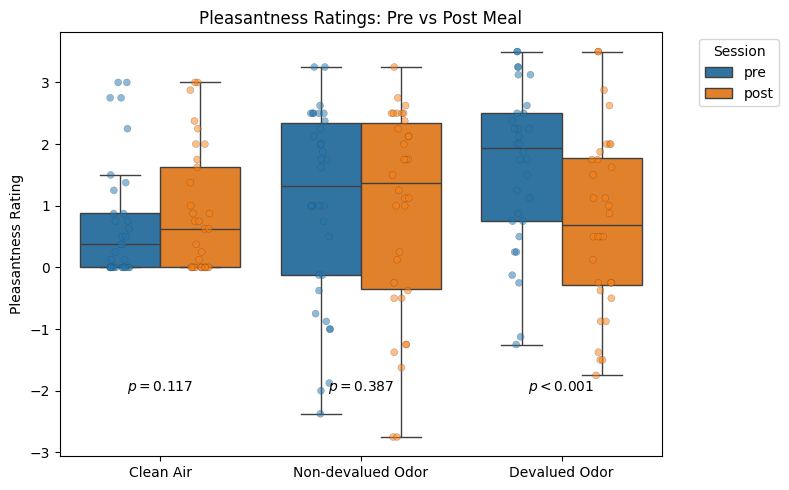

In [5]:
# === Plot ===
plt.figure(figsize=(8, 5))
sns.boxplot(data=melted, x='odor_num', y='pleasantness', hue='session', fliersize=0, linewidth=1)
sns.stripplot(data=melted, x='odor_num', y='pleasantness', hue='session', 
              dodge=True, jitter=True, alpha=0.5, linewidth=0.3, edgecolor='gray')

# Clean up legend
handles, labels = plt.gca().get_legend_handles_labels()
plt.legend(handles[:2], labels[:2], title='Session', bbox_to_anchor=(1.05, 1), loc='upper left')

# Add p-value annotations
for i, row in stat_df.iterrows():
    x = i  # odor_num corresponds to x-axis category
    y = -2
    pval = row['pval']
    label = f"$p = {pval:.3f}$" if pval >= 0.001 else "$p < 0.001$"
    plt.text(x, y, label, ha='center', fontsize=10)

plt.title('Pleasantness Ratings: Pre vs Post Meal')
plt.xlabel('')
plt.ylabel('Pleasantness Rating')
odor_labels = {
    0: 'Clean Air',
    1: 'Non-devalued Odor',
    2: 'Devalued Odor'
}
plt.xticks(ticks=[0, 1, 2], labels=[odor_labels[i] for i in [0, 1, 2]])
plt.tight_layout()
plt.show()

### plot the mean and error bars

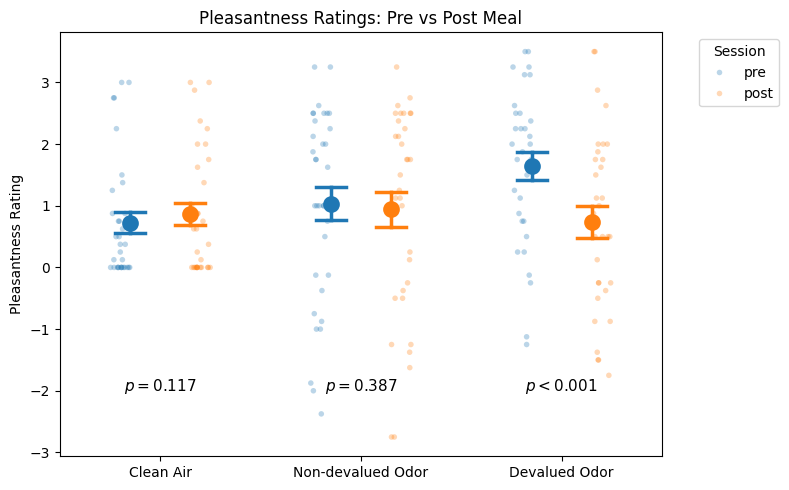

In [11]:
plt.figure(figsize=(8, 5))

# First: individual data points (in the background)
sns.stripplot(
    data=melted, x='odor_num', y='pleasantness', hue='session',
    dodge=True, jitter=True, alpha=0.3, size=4, linewidth=0, edgecolor=None
)

# Then: mean ± SE, larger and on top
sns.pointplot(
    data=melted, x='odor_num', y='pleasantness', hue='session',
    dodge=0.3, capsize=0.15, errorbar='se', markers='o', 
    err_kws={'linewidth': 2.5}, markersize=10, linestyle='none'
)

# Remove duplicate legend entries
handles, labels = plt.gca().get_legend_handles_labels()
plt.legend(handles[:2], labels[:2], title='Session', bbox_to_anchor=(1.05, 1), loc='upper left')

# Add p-value annotations
for i, row in stat_df.iterrows():
    x = i
    y = -2
    pval = row['pval']
    label = f"$p = {pval:.3f}$" if pval >= 0.001 else "$p < 0.001$"
    plt.text(x, y, label, ha='center', fontsize=11, style='italic')

plt.title('Pleasantness Ratings: Pre vs Post Meal')
plt.xlabel('')
plt.ylabel('Pleasantness Rating')
odor_labels = {
    0: 'Clean Air',
    1: 'Non-devalued Odor',
    2: 'Devalued Odor'
}
plt.xticks(ticks=[0, 1, 2], labels=[odor_labels[i] for i in [0, 1, 2]])
plt.tight_layout()
plt.show()


### Summary of Results

The boxplot compares pleasantness ratings for three types of odors — **Clean Air**, **Non-devalued Odor**, and **Devalued Odor** — before and after a meal. 

- **Clean Air**: No significant change in pleasantness rating (*p* = 0.117)  
- **Non-devalued Odor**: No significant change (*p* = 0.387)  
- **Devalued Odor**: Significant decrease in pleasantness rating (**p < 0.001**)

These results indicate a specific devaluation effect, where the odor associated with the consumed food becomes less pleasant after eating.
